# Tipos de visualizações

Este notebook mostra como criar cada tipo de gráfico visto na aula. O objetivo é mostrar o código mínimo de cada um, sem ajustes finos de estética.

- **matplotlib** para os gráficos básicos (barras, histograma, dispersão, linhas, pizza).
- **seaborn** para gráficos mais específicos (densidade, ECDF, boxplot, violino, mapa de calor, matriz de dispersão). 

Os conjuntos de dados vêm do próprio seaborn. A função `sns.load_dataset` baixa o arquivo da internet na primeira vez que for chamada.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.rcParams["font.size"] = 12

## 1. Quantidades

Dados de pinguins de três espécies, com medidas do corpo e o sexo de cada animal.

In [3]:
penguins = sns.load_dataset("penguins")
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


### Barras horizontais, ordenadas pelo valor

Text(0.5, 0, 'Massa média (g)')

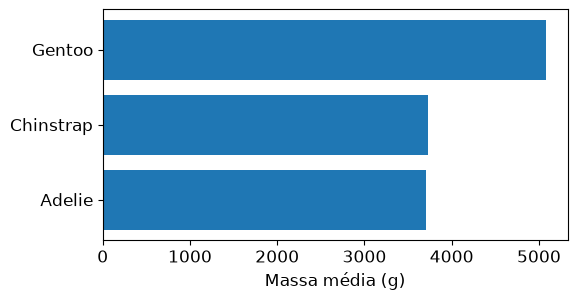

In [4]:
mean_mass = penguins.groupby("species")["body_mass_g"].mean().sort_values()

fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(mean_mass.index, mean_mass.values)
ax.set_xlabel("Massa média (g)")

### Barras agrupadas

No seaborn, `hue` define a variável mapeada na cor. `errorbar=None` desliga as barras de erro que o seaborn desenha por padrão.

Text(0, 0.5, 'Massa média (g)')

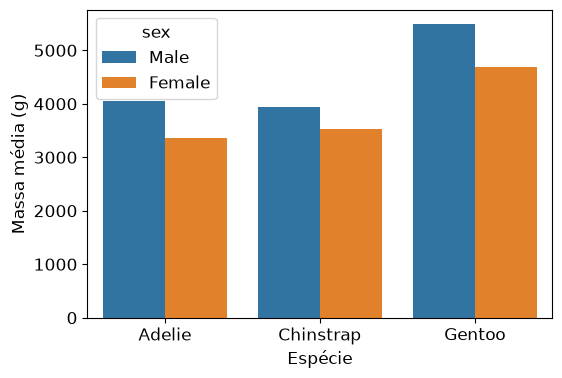

In [40]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(data=penguins, x="species", y="body_mass_g", hue="sex", errorbar=None, ax=ax)
ax.set_xlabel("Espécie")
ax.set_ylabel("Massa média (g)")

### Painéis

`catplot` com `col` cria um painel para cada valor da variável. Funções do seaborn que criam painéis criam a própria figura, sem `ax`.

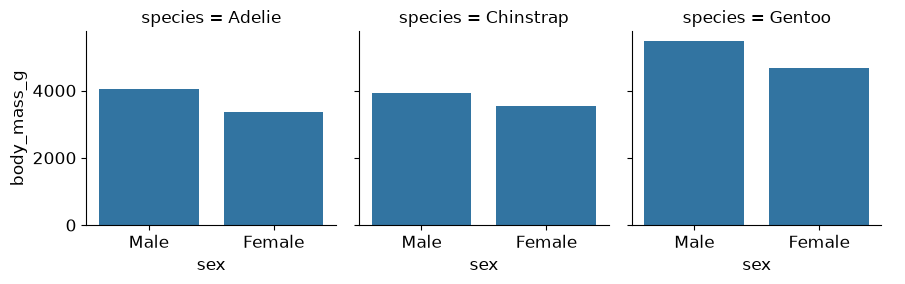

In [6]:
sns.catplot(data=penguins, x="sex", y="body_mass_g", col="species", kind="bar", errorbar=None, height=3)

### Pontos

Quando os valores estão longe do zero, pontos mostram melhor as diferenças do que barras. Expectativa de vida em 2020 para seis países.

Text(0.5, 0, 'Expectativa de vida (anos)')

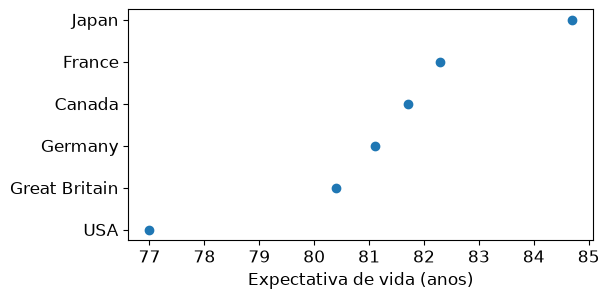

In [7]:
healthexp = sns.load_dataset("healthexp")
life_2020 = healthexp[healthexp["Year"] == 2020].sort_values("Life_Expectancy")

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(life_2020["Life_Expectancy"], life_2020["Country"], "o")
ax.set_xlabel("Expectativa de vida (anos)")

### Mapa de calor

Número de passageiros de uma companhia aérea por mês e ano. O `pivot` coloca os meses nas linhas e os anos nas colunas.

<Axes: xlabel='year', ylabel='month'>

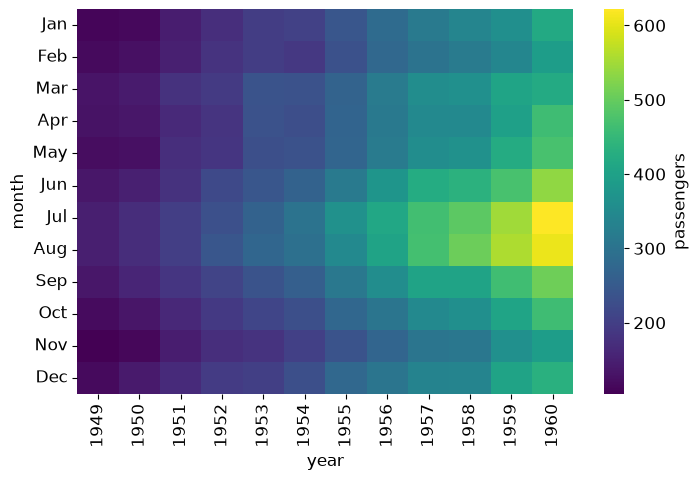

In [43]:
flights = sns.load_dataset("flights")
table = flights.pivot(index="month", columns="year", values="passengers")

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(table, cmap="viridis", ax=ax, cbar_kws={"label": "passengers"})

## 2. Distribuições

Idades dos passageiros do Titanic. A idade é desconhecida para alguns passageiros, então removemos os valores ausentes.

In [9]:
titanic = sns.load_dataset("titanic")
ages = titanic["age"].dropna()

### Histogramas com diferentes larguras de intervalo

Text(0.5, 1.0, '15 anos')

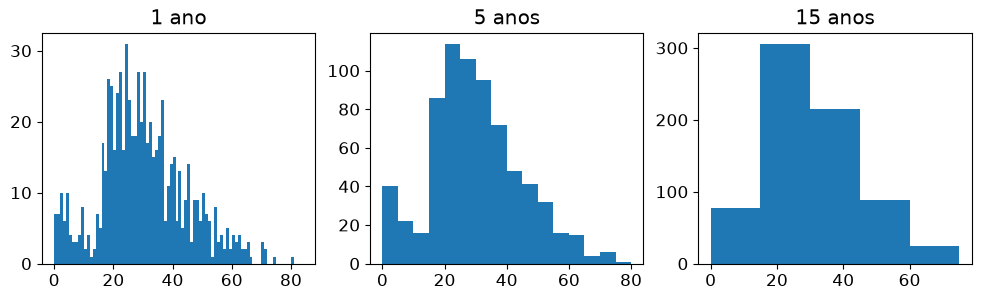

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
axs[0].hist(ages, bins=range(0, 85, 1))
axs[1].hist(ages, bins=range(0, 85, 5))
axs[2].hist(ages, bins=range(0, 85, 15))
axs[0].set_title("1 ano")
axs[1].set_title("5 anos")
axs[2].set_title("15 anos")

### Densidade

`bw_adjust` multiplica a largura de banda padrão. `cut=0` impede que a curva passe dos valores mínimo e máximo dos dados (idades negativas, por exemplo).

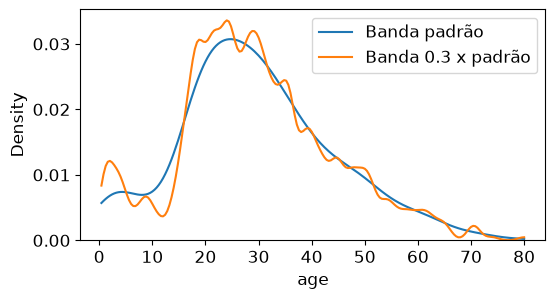

In [11]:
fig, ax = plt.subplots(figsize=(6, 3))
sns.kdeplot(data=titanic, x="age", cut=0, label="Banda padrão", ax=ax)
sns.kdeplot(data=titanic, x="age", cut=0, bw_adjust=0.3, label="Banda 0.3 x padrão", ax=ax)
ax.legend()

### Várias distribuições

Com `hue`, uma curva para cada grupo. Por padrão, a área de cada curva é proporcional ao tamanho do grupo.

<Axes: xlabel='age', ylabel='Density'>

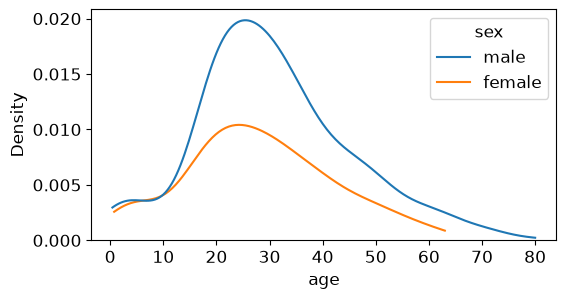

In [12]:
fig, ax = plt.subplots(figsize=(6, 3))
sns.kdeplot(data=titanic, x="age", hue="sex", cut=0, ax=ax)

### ECDF

<Axes: xlabel='age', ylabel='Proportion'>

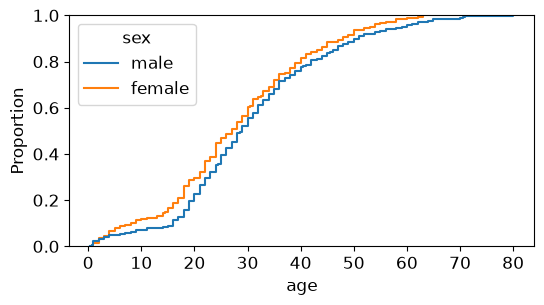

In [13]:
fig, ax = plt.subplots(figsize=(6, 3))
sns.ecdfplot(data=titanic, x="age", hue="sex", ax=ax)

### Gráfico q-q

Compara os quantis das idades com os de uma distribuição normal. O seaborn não tem esse gráfico, então usamos a função `probplot` do SciPy.

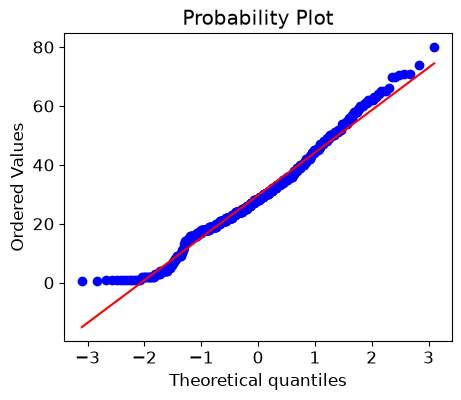

In [44]:
fig, ax = plt.subplots(figsize=(5, 4))
stats.probplot(ages, dist="norm", plot=ax);

## 3. Muitas distribuições

Extensão do gelo marinho no Ártico (em milhões de km²), medida a cada um ou dois dias de 1980 a 2019. Criamos uma coluna com o mês de cada medida.

In [15]:
seaice = sns.load_dataset("seaice")
seaice["month"] = seaice["Date"].dt.month
seaice.head()

,Date,Extent,month
0,1980-01-01,14.200,1
1,1980-01-03,14.302,1
2,1980-01-05,14.414,1
3,1980-01-07,14.518,1
4,1980-01-09,14.594,1


### Boxplot

Text(0, 0.5, 'Extensão (milhões de km²)')

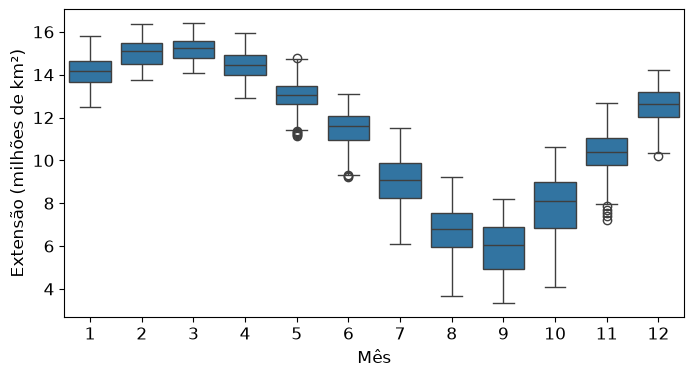

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=seaice, x="month", y="Extent", ax=ax)
ax.set_xlabel("Mês")
ax.set_ylabel("Extensão (milhões de km²)")

### Violino

Text(0, 0.5, 'Extensão (milhões de km²)')

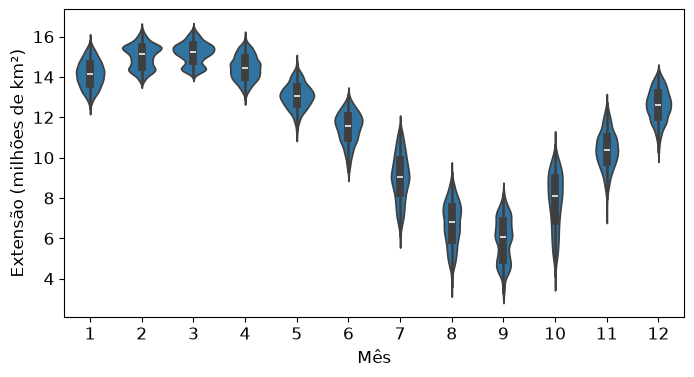

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.violinplot(data=seaice, x="month", y="Extent", ax=ax)
ax.set_xlabel("Mês")
ax.set_ylabel("Extensão (milhões de km²)")

### Pontos com *jitter*

Com poucos dados, podemos mostrar cada medida. Usamos só o ano de 2019.

Text(0, 0.5, 'Extensão (milhões de km²)')

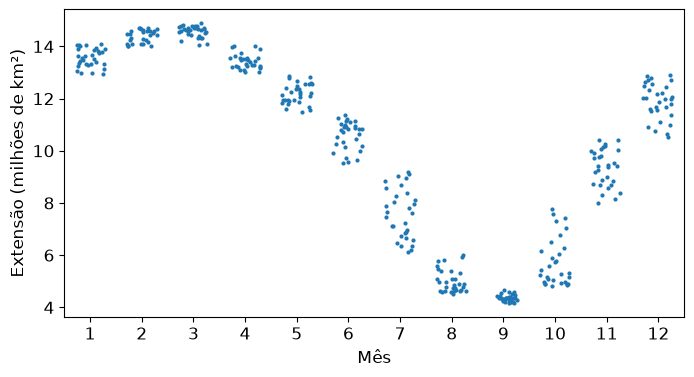

In [18]:
seaice_2019 = seaice[seaice["Date"].dt.year == 2019]

fig, ax = plt.subplots(figsize=(8, 4))
sns.stripplot(data=seaice_2019, x="month", y="Extent", jitter=0.3, size=3, ax=ax)
ax.set_xlabel("Mês")
ax.set_ylabel("Extensão (milhões de km²)")

## 4. Associações

### Dispersão com uma terceira variável como cor

Text(0, 0.5, 'Comprimento da nadadeira (mm)')

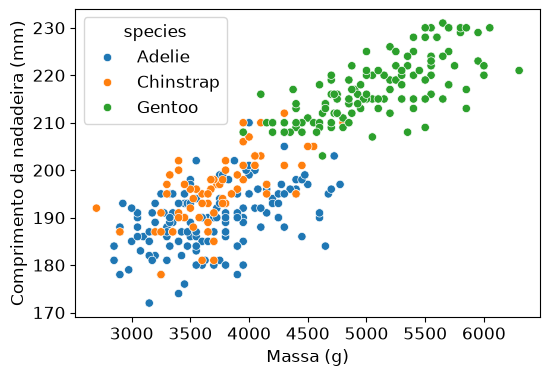

In [25]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.scatterplot(data=penguins, x="body_mass_g", y="flipper_length_mm", hue="species", ax=ax)
ax.set_xlabel("Massa (g)")
ax.set_ylabel("Comprimento da nadadeira (mm)")

### Matriz de dispersão

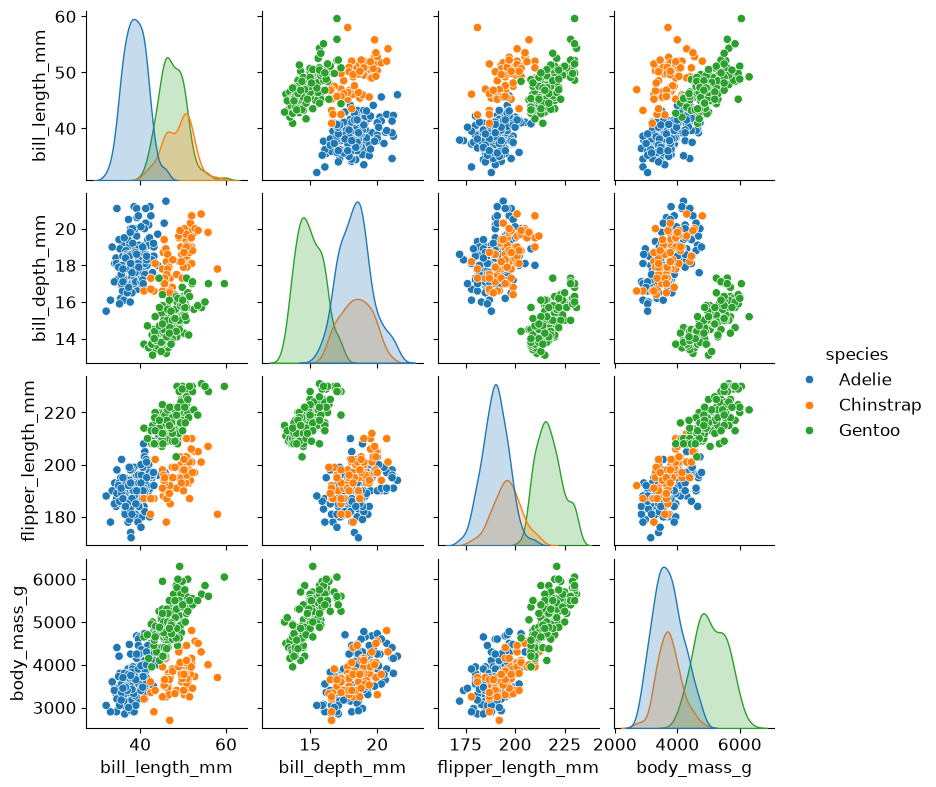

In [26]:
sns.pairplot(penguins, hue="species", height=2)

### Correlograma

A correlação vai de -1 a 1, então usamos uma escala divergente com o zero no meio (`vmin=-1`, `vmax=1`).

<Axes: >

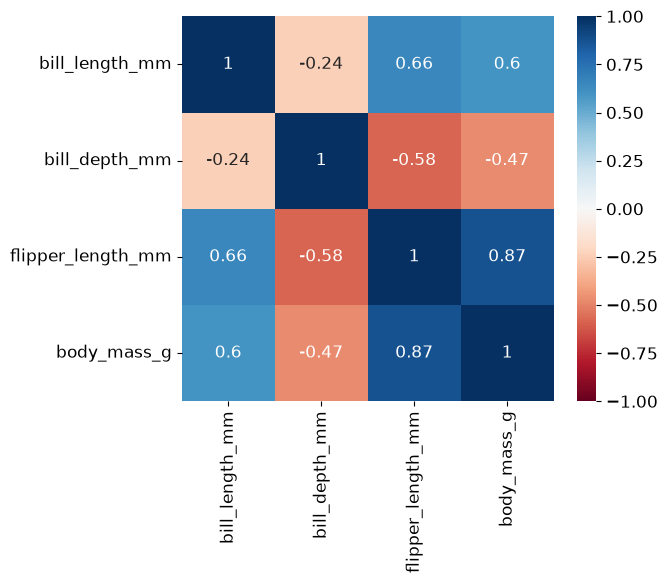

In [27]:
corr = penguins.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, cmap="RdBu", vmin=-1, vmax=1, annot=True, ax=ax)

## 5. Séries temporais

Gasto anual com saúde por pessoa (em dólares) em três países.

In [45]:
countries = ["USA", "Germany", "Japan"]
health = healthexp[healthexp["Country"].isin(countries)]

### Linhas com legenda

Text(0, 0.5, 'Gasto por pessoa (US$)')

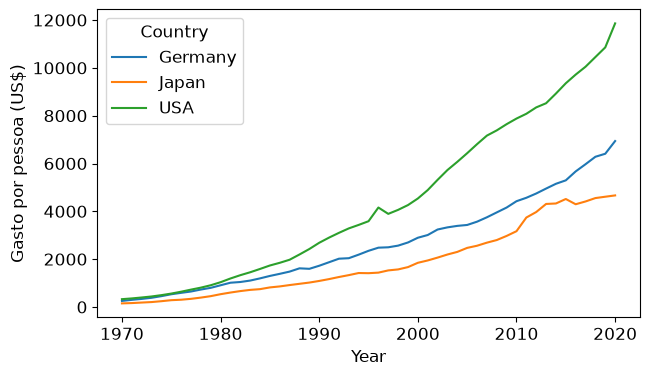

In [31]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.lineplot(data=health, x="Year", y="Spending_USD", hue="Country", ax=ax)
ax.set_ylabel("Gasto por pessoa (US$)")

### Linhas com rótulos diretos

Escrevemos o nome de cada país ao lado do último ponto da sua série.

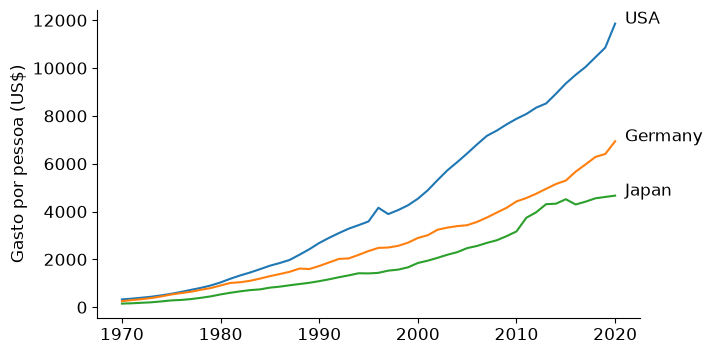

In [46]:
fig, ax = plt.subplots(figsize=(7, 4))
for country in countries:
    data = health[health["Country"] == country]
    ax.plot(data["Year"], data["Spending_USD"])
    ax.text(data["Year"].iloc[-1] + 1, data["Spending_USD"].iloc[-1], country)
ax.set_ylabel("Gasto por pessoa (US$)")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

## 6. Tendências

Valor mensal do índice Dow Jones de 1914 a 1968.

In [35]:
dowjones = sns.load_dataset("dowjones")
dowjones.head()

,Date,Price
0,1914-12-01,55.00
1,1915-01-01,56.55
2,1915-02-01,56.00
3,1915-03-01,58.30
4,1915-04-01,66.45


### Média móvel

`rolling(12, center=True).mean()` calcula a média usando 12 meses ao redor de cada ponto. Com `center=True`, a janela fica centrada em cada ponto.

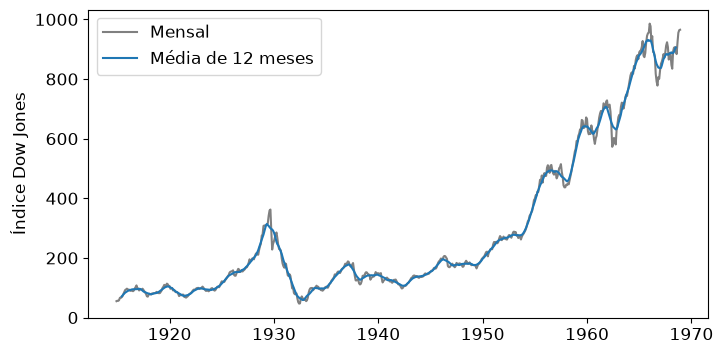

In [55]:
dowjones["mean_12"] = dowjones["Price"].rolling(12, center=True).mean()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(dowjones["Date"], dowjones["Price"], color="grey", label="Mensal")
ax.plot(dowjones["Date"], dowjones["mean_12"], label="Média de 12 meses")
ax.set_ylabel("Índice Dow Jones")
ax.legend()